Train a weak model → focus more on the mistakes → train another model → focus on its mistakes → combine them.

In [2]:
import sklearn
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

In [1]:
from sklearn import datasets

In [3]:
iris = datasets.load_iris()
print(iris.DESCR)

.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

In [5]:
X=iris.data
Y=iris.target
X.shape , Y.shape

((150, 4), (150,))

In [6]:
from sklearn.model_selection import train_test_split

In [ ]:
X_train, X_test, Y_train, Y_test = train_test_split(X,Y,train_size=0.8,random_state=42,stratify=Y)  
#This tries to maintain the same class proportions in train and test.

In [10]:
from sklearn.ensemble import AdaBoostClassifier

In [ ]:
model = AdaBoostClassifier(n_estimators = 50, learning_rate=1, random_state=43 )
#Learning Rate Controls how strongly each new learner contributes to the final model.

In [36]:
model.fit(X_train, Y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given at each `estimator` at eachboosting iteration.Thus, it is only used when `estimator` exposes a `random_state`.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",43
,"estimator estimator: object, default=NoneThe base estimator from which the boosted ensemble is built.Support for sample weighting is required, as well as proper``classes_`` and ``n_classes_`` attributes. If ``None``, thenthe base estimator is :class:`~sklearn.tree.DecisionTreeClassifier`initialized with `max_depth=1`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",None
,"n_estimators n_estimators: int, default=50The maximum number of estimators at which boosting is terminated.In case of perfect fit, the learning procedure is stopped early.Values must be in the range `[1, inf)`.",50
,"learning_rate learning_rate: float, default=1.0Weight applied to each classifier at each boosting iteration. A higherlearning rate increases the contribution of each classifier. There isa trade-off between the `learning_rate` and `n_estimators` parameters.Values must be in the range `(0.0, inf)`.",1
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[int64](3,)","[0,1,2]"
estimator_ estimator_: estimatorThe base estimator from which the ensemble is grown... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,DecisionTreeClassifier,DecisionTreeC...r(max_depth=1)
estimator_errors_ estimator_errors_: ndarray of floatsClassification error for each estimator in the boostedensemble.,"ndarray[float64](50,)","[0.33,0.18,0.1 ,...,0.33,0.33,0.33]"
estimator_weights_ estimator_weights_: ndarray of floatsWeights for each estimator in the boosted ensemble.,"ndarray[float64](50,)","[1.39,2.19,2.85,...,1.39,1.39,1.39]"
estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators.,list,"[DecisionTreeC...ate=494155588), DecisionTreeC...te=2134003008), DecisionTreeC...ate=468437247), DecisionTreeC...ate=442015537), ...]"
"feature_importances_ feature_importances_: ndarray of shape (n_features,)The impurity-based feature importances if supported by the``estimator`` (when based on decision trees).Warning: impurity-based feature importances can be misleading forhigh cardinality features (many unique values). See:func:`sklearn.inspection.permutation_importance` as an alternative.","ndarray[float64](4,)","[0.1 ,0.06,0.39,0.45]"


In [37]:
Y_pred = model.predict(X_test)
Y_pred 

array([0, 2, 1, 1, 0, 1, 0, 0, 2, 1, 2, 2, 2, 1, 0, 0, 0, 1, 1, 2, 0, 2,
       1, 1, 2, 2, 1, 0, 2, 0])

In [38]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [39]:
accuracy_score(Y_test, Y_pred)

0.9333333333333333

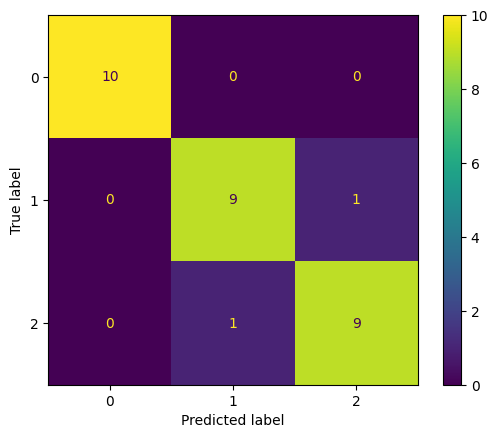

In [17]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(Y_test, Y_pred)
plt.show()

In [18]:
print(classification_report(Y_test, Y_pred) )

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       0.90      0.90      0.90        10
           2       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



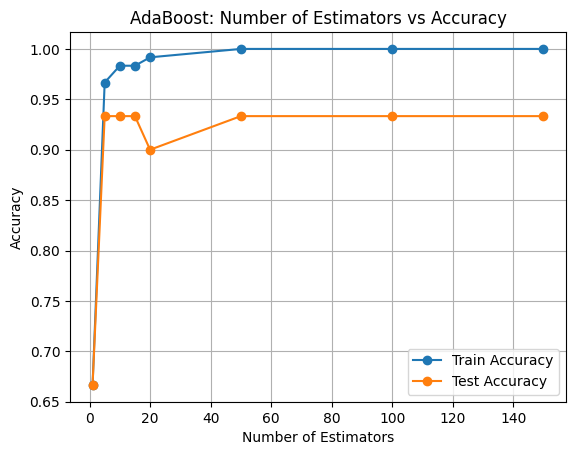

In [19]:
estimators = [1,5,10,15,20,50,100,150]

train_acc = []
test_acc = []

for n in estimators:
    model = AdaBoostClassifier(n_estimators = n, learning_rate = 1, random_state = 42)
    model.fit(X_train,Y_train)

    train_acc.append(model.score(X_train, Y_train))
    test_acc.append(model.score(X_test, Y_test))

plt.plot(estimators ,train_acc, marker='o', label="Train Accuracy" )
plt.plot(estimators ,test_acc, marker='o', label="Test Accuracy" )

plt.xlabel("Number of Estimators")
plt.ylabel("Accuracy")
plt.title("AdaBoost: Number of Estimators vs Accuracy")

plt.legend()
plt.grid()

plt.show()

In [20]:
from sklearn.model_selection import GridSearchCV

params = {"n_estimators":[5,15,50,80,100] , "learning_rate":[0.01,0.1,1]}

grid = GridSearchCV(AdaBoostClassifier(random_state=42), params, scoring='accuracy', cv=5)
model1=grid.fit(X_train,Y_train)

In [22]:
Y_pred1=model1.predict(X_test)
Y_pred1

array([0, 2, 1, 1, 0, 1, 0, 0, 2, 1, 2, 2, 2, 1, 0, 0, 0, 1, 1, 2, 0, 2,
       1, 1, 2, 2, 1, 0, 2, 0])

In [23]:
accuracy_score(Y_test, Y_pred1)

0.9333333333333333

In [25]:
print(grid.best_estimator_)

AdaBoostClassifier(learning_rate=1, n_estimators=5, random_state=42)


In [28]:
print(grid.best_params_)

{'learning_rate': 1, 'n_estimators': 5}


In [ ]:
print(grid.best_score_)  #best CrossValidation score

0.9583333333333334
